# 02 · Linear systems, low-rank completion and PDE inpainting
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mvya0005/mma3001-project-sensor-reconstruction/blob/main/notebooks/02_linear_algebra_and_pde_inpainting.ipynb)

| Unit topic | Where |
|---|---|
| 2.1 Optimisation and profiling | Thomas vs dense solve scaling; Python Gauss-Seidel loop vs sparse direct solve |
| 2.3 Systems of linear equations | tridiagonal spline system, Gaussian elimination with pivoting, condition numbers |
| Workshop 2: SVD and singular values | low-rank structure of the day × time-of-day matrix; SVD matrix completion |
| 10.1 Relaxation for boundary-value problems | Jacobi, Gauss-Seidel and SOR for the Laplace fill, with a convergence criterion |
| 10.4 Classifying PDEs | elliptic (Laplace) vs parabolic (diffusion) formulations of the same fill |
| 11.1, 11.4, 11.5 FTCS, stability, Crank–Nicolson | pseudo-time diffusion fill, with the stability limit measured |
| 11.2 Boundary conditions | Dirichlet (observed readings), Neumann (open series end), helical periodic (time of day) |
| 11.3 Elliptic PDEs | 2-D Laplace inpainting coupled across days |

In [1]:
# ---- Environment setup: works on Google Colab and locally ----
import os, sys, subprocess
from pathlib import Path

GITHUB_REPO = "mvya0005/mma3001-project-sensor-reconstruction"  # owner/name of this repository
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo_dir = Path("/content") / GITHUB_REPO.split("/")[1]
    if not repo_dir.exists():
        subprocess.run(["git", "clone", "-q", f"https://github.com/{GITHUB_REPO}.git", str(repo_dir)], check=True)
    os.chdir(repo_dir)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
    sys.path.insert(0, str(repo_dir / "src"))  # editable install is not visible until restart
    from google.colab import drive
    drive.mount("/content/drive")
    RAW = Path("/content/drive/MyDrive/MMA3001/raw")              # put the two Moodle zip files here
    PROCESSED = Path("/content/drive/MyDrive/MMA3001/processed")  # cached across Colab sessions
else:
    if Path.cwd().name == "notebooks":
        os.chdir("..")
    sys.path.insert(0, str(Path("src").resolve()))
    RAW, PROCESSED = Path("data/raw"), Path("data/processed")

PROCESSED.mkdir(parents=True, exist_ok=True)
if not (PROCESSED / "audit.json").exists():
    subprocess.run([sys.executable, "scripts/preprocess.py", "--raw", str(RAW), "--out", str(PROCESSED)], check=True)
print("repository:", Path.cwd(), "| processed data:", PROCESSED)

repository: /home/claude/mma3001-sensor-reconstruction | processed data: data/processed


In [2]:
import time
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sensorfill import benchmark as bm, interpolation as itp, linalg, pde, profiling, study, plotting
from sensorfill.plotting import plt
plotting.setup()
co2, temp = study.load_study(PROCESSED, "co2"), study.load_study(PROCESSED, "temp")

## 1. The spline system: why a tridiagonal solver

The natural cubic spline's second derivatives satisfy a symmetric, strictly diagonally dominant tridiagonal system. Gaussian elimination on the dense matrix costs about ⅔n³ flops. The Thomas algorithm exploits the band and costs about 8n flops, needing no pivoting because of the diagonal dominance. Both are timed below and checked against LAPACK (`numpy.linalg.solve`).

In [3]:
rng = np.random.default_rng(0)
rows = []
for n in (50, 100, 200, 400, 800, 1600):
    h = rng.uniform(0.5, 1.5, n + 1)
    a = np.r_[0, h[1:-1]]; b = 2 * (h[:-1] + h[1:]); c = np.r_[h[1:-1], 0]; d = rng.normal(size=n)
    A = np.diag(b) + np.diag(a[1:], -1) + np.diag(c[:-1], 1)
    t_th = profiling.measure(linalg.thomas_solve, a, b, c, d, repeats=3)
    t_np = profiling.measure(np.linalg.solve, A, d, repeats=3)
    t_ge = profiling.measure(linalg.gauss_solve, A, d, repeats=1) if n <= 800 else None
    x = t_th.result
    rows.append({"n": n, "Thomas [ms]": 1e3 * t_th.median_s, "LAPACK dense [ms]": 1e3 * t_np.median_s,
                 "own Gauss+pivot [ms]": 1e3 * t_ge.median_s if t_ge else np.nan,
                 "rel. residual ||Ax-d||/||d||": np.linalg.norm(A @ x - d) / np.linalg.norm(d),
                 "cond2(A)": linalg.condition_number(A) if n <= 800 else np.nan})
solv = pd.DataFrame(rows).set_index("n"); solv

,Thomas [ms],LAPACK dense [ms],own Gauss+pivot [ms],rel. residual ||Ax-d||/||d||,cond2(A)
n,,,,,
50,0.093823,0.055802,2.174473,9.572380e-17,4.993298
100,0.177673,0.189347,9.115781,1.335299e-16,4.690896
200,0.337242,0.461574,31.399747,1.401553e-16,5.231226
400,0.764164,105.960647,272.842608,1.471881e-16,5.629388
800,1.357040,933.831451,1190.939192,1.356135e-16,5.338532
1600,2.479650,221.596407,NaN,1.365190e-16,NaN


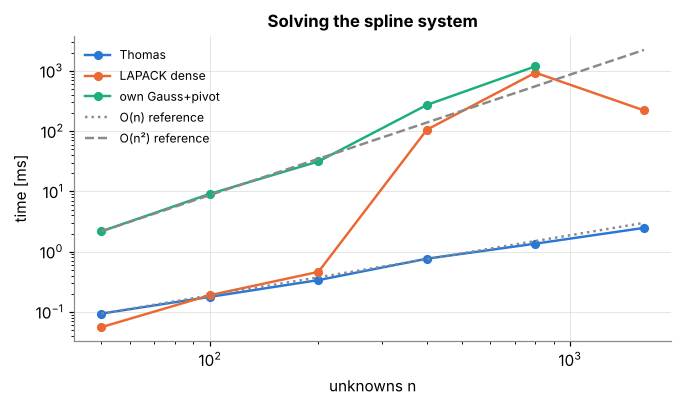

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, col in enumerate(["Thomas [ms]", "LAPACK dense [ms]", "own Gauss+pivot [ms]"]):
    ax.loglog(solv.index, solv[col], marker="o", color=plotting.PALETTE[i], label=col.replace(" [ms]", ""))
n = solv.index.to_numpy(float)
ax.loglog(n, solv["Thomas [ms]"].iloc[0] * n / n[0], ":", color=plotting.MUTED, label="O(n) reference")
ax.loglog(n, solv["own Gauss+pivot [ms]"].iloc[0] * (n / n[0]) ** 2, "--", color=plotting.MUTED, label="O(n²) reference")
ax.set_xlabel("unknowns n"); ax.set_ylabel("time [ms]"); ax.legend(fontsize=8); ax.set_title("Solving the spline system")
_ = plotting.save(fig, "02_solver_scaling")

**Observations.** The condition number of the spline matrix stays small (about 5) at every size, so all three solvers are accurate to about 10⁻¹⁵. The differences are entirely in cost. Our Gaussian elimination is far slower than the others, and its time grows by a factor of 7–10 per doubling of n, approaching the n³ scaling of its ⅔n³ flops. Each elimination step is vectorised over the remaining sub-matrix, so the Python loop count is only O(n), but the arithmetic is not reduced. LAPACK's dense solve is O(n³) but optimised, so it is quick for small n. Thomas is O(n) but runs as a Python loop, so a *compiled* O(n) implementation could be much faster still (not measured here). This illustrates the gap between operation counts and wall-clock time that the roofline analysis in notebook 06 makes quantitative.

## 2. Low-rank structure and SVD completion

Fold the training CO₂ into a matrix *M* (days × 144 slots). If buildings repeat their daily schedule, *M* is approximately low rank: $M \approx U_k S_k V_k^T$ with a few "typical day" patterns (columns of *V*), each weighted per day (columns of *U S*). `svd_impute` alternates between a rank-*k* SVD and overwriting only the missing entries (hard-impute).

co2: 61 complete days; rank for 80% / 90% of variance: 3 / 6
temp: 61 complete days; rank for 80% / 90% of variance: 2 / 3


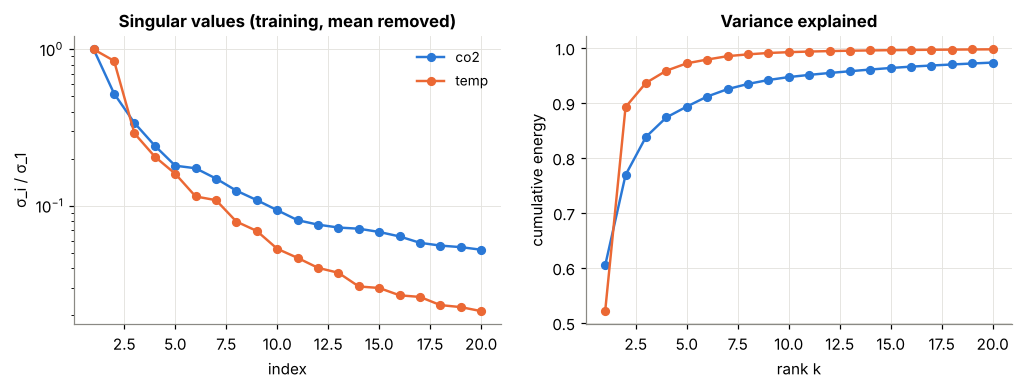

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for i, s in enumerate((co2, temp)):
    y, ts, _ = s.part("train")
    off = bm.Context(ts=ts).midnight_offset
    M = linalg.fold_daily(itp.fill_linear(y), study.STEPS_PER_DAY, off)
    M = M[~np.isnan(M).any(axis=1)]
    sv = np.linalg.svd(M - M.mean(), compute_uv=False)
    energy = np.cumsum(sv**2) / np.sum(sv**2)
    axes[0].semilogy(np.arange(1, 21), sv[:20] / sv[0], marker="o", color=plotting.PALETTE[i], label=s.variable)
    axes[1].plot(np.arange(1, 21), energy[:20], marker="o", color=plotting.PALETTE[i], label=s.variable)
    print(f"{s.variable}: {M.shape[0]} complete days; rank for 80% / 90% of variance: "
          f"{np.searchsorted(energy, 0.8) + 1} / {np.searchsorted(energy, 0.9) + 1}")
axes[0].set_xlabel("index"); axes[0].set_ylabel("σ_i / σ_1"); axes[0].set_title("Singular values (training, mean removed)"); axes[0].legend()
axes[1].set_xlabel("rank k"); axes[1].set_ylabel("cumulative energy"); axes[1].set_title("Variance explained")
_ = plotting.save(fig, "02_singular_values")

The spectrum decays slowly after the first few values. The day-to-day variation in this room is *not* strongly low rank, so SVD completion has less to exploit than the textbook case. The rank is chosen on validation data below, with convergence monitored through the relative change of the filled entries.

In [6]:
yv, tv, _ = co2.part("val")
ctx_v = bm.Context(ts=tv)
svd_c = {f"SVD k={k}": bm.svd_method(k) for k in (1, 2, 3, 5, 8)}
svd_c["Linear"] = lambda y, c: itp.fill_linear(y)
svd_tab = bm.summarise(bm.run_benchmark(yv, ctx_v, svd_c, repeats=2, seed=5)).round(1); svd_tab

gap_len,1,3,6,18,36,72,144
method,,,,,,,
SVD k=3,16.3,18.0,18.7,19.0,39.1,45.8,38.0
Linear,9.7,9.7,12.7,17.4,21.3,31.5,39.1
SVD k=5,14.3,15.8,16.0,26.2,42.9,40.7,41.2
SVD k=8,18.5,19.2,21.2,41.3,40.3,40.6,42.8
SVD k=2,19.0,20.7,23.9,23.1,26.2,45.9,43.4
SVD k=1,25.2,30.0,28.3,28.5,32.4,33.9,45.2


SVD completion is worse than plain linear interpolation for every gap length up to 12 h and only roughly ties at 24 h, whatever the rank. A low-rank model of *whole days* cannot reproduce the short-term level of a particular day near a gap, while linear interpolation is anchored to it. **SVD completion is therefore not carried forward for CO₂.** This negative result is itself evidence that the room's CO₂ is driven by irregular occupancy rather than a fixed schedule.

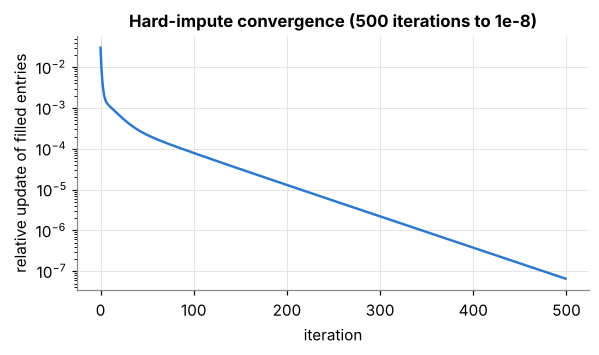

In [7]:
from sensorfill.masking import block_mask, apply_mask
m = block_mask(~np.isnan(yv), 72, 6, np.random.default_rng(0), margin=2, min_observed=0.8)
Mv = linalg.fold_daily(apply_mask(yv, m), 144, ctx_v.midnight_offset)
_, hist, _ = linalg.svd_impute(Mv, rank=3, max_iter=500, tol=1e-8, return_history=True)
fig, ax = plt.subplots(figsize=(6, 3)); ax.semilogy(hist, color=plotting.PALETTE[0])
ax.set_xlabel("iteration"); ax.set_ylabel("relative update of filled entries"); ax.set_title(f"Hard-impute convergence ({len(hist)} iterations to 1e-8)")
_ = plotting.save(fig, "02_svd_convergence")

The update decreases monotonically (roughly linearly on the log axis, i.e. geometric convergence), which confirms the iteration is stable. The default tolerance of 10⁻⁵ is reached well before the iteration cap.

## 3. Gap filling as a boundary-value problem

**Classification (10.4).** Treat the unknown values $u$ in a gap as a field with the observed readings as **Dirichlet** boundary conditions.
* **Elliptic:** $\nabla^2 u = 0$ (Laplace). Information propagates from all boundaries at once, giving the "smoothest" fill.
* **Parabolic:** $u_\tau = \nabla^2 u$ (diffusion in a pseudo-time τ). Its steady state is the Laplace solution, so marching it is another way to solve the same problem, and the stability theory of FTCS and Crank–Nicolson applies.

In 1-D (neighbours *i*±1 only) the discrete Laplace solution is *exactly* the straight line. That gives an analytical check of every solver. In "2-D" each point is also coupled to *i*±144, the same time on the previous and next day (weight *w*). Folding into the day image, this is the 5-point Laplacian with a **helical periodic** boundary on the time-of-day axis (23:50 connects to 00:00 of the next day). At the ends of the series only one side is observed, which acts as a zero-flux (**Neumann**) boundary.

In [8]:
y = np.r_[np.linspace(400, 420, 6), np.full(40, np.nan), np.linspace(480, 470, 6)]
ref = itp.fill_linear(y)
rows = []
for meth in ("jacobi", "gs", "sor", "direct"):
    t0 = time.perf_counter()
    out, info = pde.laplace_fill(y, method=meth, omega=pde.optimal_sor_omega(40), tol=1e-10, return_info=True)
    rows.append({"method": meth, "iterations": info.iterations, "converged": info.converged,
                 "max |u - linear| [ppm]": np.max(np.abs(out - ref)), "time [ms]": 1e3 * (time.perf_counter() - t0)})
pd.DataFrame(rows)

,method,iterations,converged,max |u - linear| [ppm],time [ms]
0,jacobi,5677,True,5.459006e-07,69.104405
1,gs,2719,True,1.352382e-06,278.764915
2,sor,164,True,4.476072e-08,14.046762
3,direct,1,True,2.728484e-12,1.883929


**Convergence criterion.** Iteration stops when the largest update is below `tol` × (data range). Scaling by the range makes the criterion unit-independent (ppm vs °C). All four solvers reproduce the analytical solution to the requested tolerance.

### Relaxation speed: Jacobi vs Gauss–Seidel vs SOR
For the 1-D Dirichlet problem with *m* unknowns, the Jacobi iteration matrix has spectral radius ρ = cos(π/(m+1)). Gauss–Seidel converges twice as fast (ρ²), and SOR with $\omega^* = 2/(1+\sqrt{1-\rho^2})$ reduces the iteration count from O(m²) to O(m).

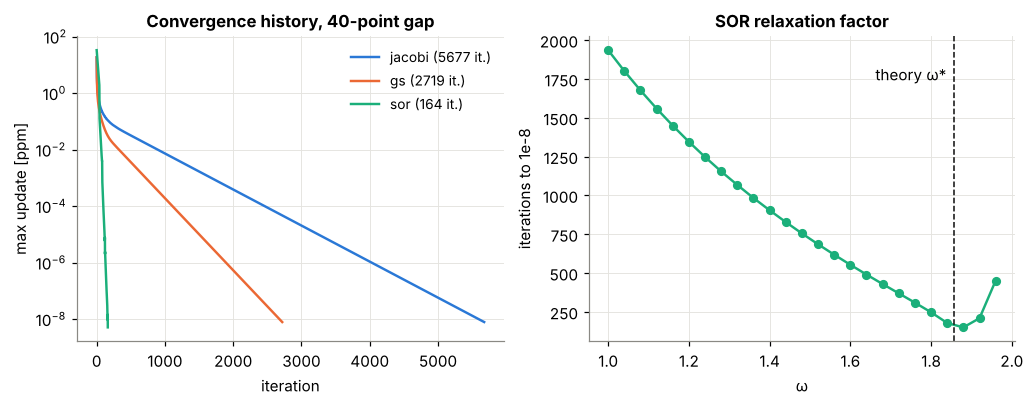

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for i, meth in enumerate(("jacobi", "gs", "sor")):
    _, info = pde.laplace_fill(y, method=meth, omega=pde.optimal_sor_omega(40), tol=1e-10, return_info=True)
    axes[0].semilogy(info.residuals, color=plotting.PALETTE[i], label=f"{meth} ({info.iterations} it.)")
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("max update [ppm]"); axes[0].legend(); axes[0].set_title("Convergence history, 40-point gap")
omegas = np.round(np.arange(1.0, 1.99, 0.04), 2)
its = [pde.laplace_fill(y, method="sor", omega=w, tol=1e-8, return_info=True)[1].iterations for w in omegas]
axes[1].plot(omegas, its, marker="o", color=plotting.PALETTE[2])
axes[1].axvline(pde.optimal_sor_omega(40), color=plotting.INK, ls="--", lw=1)
axes[1].text(pde.optimal_sor_omega(40) - 0.02, max(its) * 0.9, "theory ω*", ha="right")
axes[1].set_xlabel("ω"); axes[1].set_ylabel("iterations to 1e-8"); axes[1].set_title("SOR relaxation factor")
_ = plotting.save(fig, "02_relaxation")

The measured optimum agrees with the theoretical ω* (≈ 1.86 for 40 unknowns). Over-relaxing past it makes the iteration oscillate and slows it down again.

## 4. Diffusion in pseudo-time: FTCS stability and Crank–Nicolson
FTCS (explicit) is stable only when $r = D\,\Delta\tau/\Delta x^2 \le 1/\text{max degree}$: 0.5 in 1-D, and 1/(2 + 2w) with day coupling. Crank–Nicolson is unconditionally stable, so it can take large steps.

,scheme,r,steps,converged,max |u - Laplace| [ppm]
0,ftcs,0.25,6000,False,1.424669e-03
1,ftcs,0.50,4110,True,5.456158e-05
2,ftcs,0.52,276,False,4.308263e+07
3,cn,0.50,3567,True,2.716352e-04
4,cn,20.00,286,True,3.715343e-07


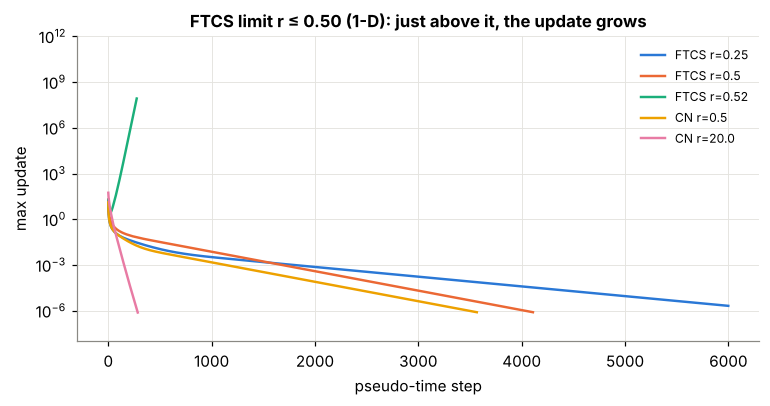

In [10]:
rows = []
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (scheme, r) in enumerate((("ftcs", 0.25), ("ftcs", 0.5), ("ftcs", 0.52), ("cn", 0.5), ("cn", 20.0))):
    out, info = pde.diffusion_fill(y, r=r, scheme=scheme, n_steps=6000, tol=1e-8, return_info=True)
    rows.append({"scheme": scheme, "r": r, "steps": info.iterations, "converged": info.converged,
                 "max |u - Laplace| [ppm]": np.max(np.abs(out - ref)) if np.isfinite(out).all() else np.inf})
    ax.semilogy(np.minimum(info.residuals, 1e12), color=plotting.PALETTE[i], label=f"{scheme.upper()} r={r}")
ax.set_xlabel("pseudo-time step"); ax.set_ylabel("max update"); ax.set_ylim(1e-8, 1e12); ax.legend(fontsize=8)
ax.set_title(f"FTCS limit r ≤ {pde.ftcs_stability_limit():.2f} (1-D): just above it, the update grows")
_ = plotting.save(fig, "02_ftcs_cn_stability")
pd.DataFrame(rows)

* FTCS at r = 0.52 (4 % above the limit) **diverges**, as the stability analysis predicts. The highest-frequency error mode is amplified by |1 − 4r| > 1 per step.
* FTCS at r = 0.5 is the largest stable step. Its highest-frequency mode is only neutrally stable (|1 − 4r| = 1), but the slow, smooth modes that set the convergence time decay fastest, so it converges in fewer steps than r = 0.25, which is stable but needs more than 6,000 steps.
* Crank–Nicolson converges for r = 20, and in far fewer steps, because each step solves a sparse linear system (factorised once with `splu`). Its steady state equals the Laplace/linear solution.

For gap filling, the steady-state elliptic solve with a sparse direct solver is the efficient route. The parabolic formulation is useful for understanding and for its stability lessons.

## 5. Day-coupled Laplace: tuning the coupling weight on validation data

In [11]:
lap = {"Linear (= 1-D Laplace)": lambda y, c: itp.fill_linear(y)}
for w in (0.05, 0.1, 0.25, 0.5, 1.0):
    lap[f"Laplace 2-D w={w}"] = (lambda w: lambda y, c: pde.laplace_fill(y, steps_per_day=144, w_day=w, method="direct"))(w)
lap_tabs = {}
for s in (co2, temp):
    ys, tss, _ = s.part("val")
    lap_tabs[s.variable] = bm.summarise(bm.run_benchmark(ys, bm.Context(ts=tss), lap, repeats=2, seed=6)).round(3)
pd.concat(lap_tabs, names=["variable"])

gap_len                             1       3       6       18      36   \
variable method                                                           
co2      Laplace 2-D w=0.05       9.321  10.790  16.655  28.207  32.636   
         Laplace 2-D w=0.1        9.708  12.949  21.339  31.427  34.517   
         Laplace 2-D w=0.25      11.584  18.836  28.076  34.725  36.780   
         Laplace 2-D w=0.5       14.989  24.533  32.146  36.500  38.210   
         Laplace 2-D w=1.0       20.060  29.715  35.006  37.766  39.315   
         Linear (= 1-D Laplace)   9.183   9.953  11.182  16.892  23.978   
temp     Laplace 2-D w=0.05       0.096   0.122   0.198   0.441   0.445   
         Laplace 2-D w=0.1        0.102   0.145   0.236   0.481   0.447   
         Laplace 2-D w=0.25       0.128   0.203   0.297   0.522   0.461   
         Laplace 2-D w=0.5        0.173   0.258   0.336   0.543   0.473   
         Laplace 2-D w=1.0        0.238   0.308   0.365   0.557   0.483   
         Linear (= 1-D Laplace)   0.094   0.107   0.159   0.435   0.772   

gap_len                             72      144  
variable method                                  
co2      Laplace 2-D w=0.05      38.160  41.684  
         Laplace 2-D w=0.1       39.218  42.546  
         Laplace 2-D w=0.25      40.260  43.388  
         Laplace 2-D w=0.5       40.839  43.856  
         Laplace 2-D w=1.0       41.296  44.222  
         Linear (= 1-D Laplace)  30.479  48.601  
temp     Laplace 2-D w=0.05       0.428   0.469  
         Laplace 2-D w=0.1        0.428   0.472  
         Laplace 2-D w=0.25       0.438   0.489  
         Laplace 2-D w=0.5        0.447   0.502  
         Laplace 2-D w=1.0        0.455   0.512  
         Linear (= 1-D Laplace)   1.232   1.476

**Interpretation.**
* For **temperature**, coupling to neighbouring days helps strongly for long gaps (24 h error falls by a factor of ~3), and the error is insensitive to *w* between 0.05 and 0.25. This is the regular daily HVAC cycle.
* For **CO₂**, any coupling *hurts* short and medium gaps. The harmonic solution is pulled towards yesterday's values, which differ by tens of ppm because occupancy differs from day to day. Only the 24 h gaps benefit slightly.
* **Choice:** w = 0.1 for temperature. For CO₂, the 2-D Laplace fill is not carried forward (the daily profile of notebook 01 dominates it).

## 6. Profiling: where does the time go?

In [12]:
ys = co2.part("val")[0].copy()
m = block_mask(~np.isnan(ys), 36, 20, np.random.default_rng(1), margin=2, min_observed=0.8)
y_in = apply_mask(ys, m)
rows = []
for meth in ("direct", "sor", "jacobi"):
    t = profiling.measure(pde.laplace_fill, y_in, steps_per_day=144, w_day=0.1, method=meth, omega=1.9, tol=1e-6, repeats=3)
    rows.append({"solver": meth, "time [s]": t.median_s, "peak Python memory [MB]": t.peak_mb})
print(pd.DataFrame(rows).to_string(index=False))
print(profiling.profile_call(pde.laplace_fill, y_in, steps_per_day=144, w_day=0.1, method="sor", omega=1.9, top=8, pattern="sensorfill|scipy|numpy|built-in"))

solver  time [s]  peak Python memory [MB]
direct  0.002661                   0.7753
   sor  0.259144                   0.7753
jacobi  0.007462                   0.7753


         241187 function calls (241182 primitive calls) in 0.430 seconds

   Ordered by: internal time
   List reduced from 323 to 209 due to restriction <'sensorfill|scipy|numpy|built-in'>
   List reduced from 209 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.191    0.191    0.215    0.215 /home/claude/mma3001-sensor-reconstruction/src/sensorfill/pde.py:89(laplace_fill)
   119274    0.023    0.000    0.023    0.000 {built-in method builtins.abs}
   119302    0.022    0.000    0.022    0.000 {built-in method builtins.max}
       23    0.001    0.000    0.001    0.000 /usr/local/lib/python3.13/dist-packages/scipy/sparse/_sputils.py:263(get_index_dtype)
       26    0.000    0.000    0.000    0.000 {method 'reduce' of 'numpy.ufunc' objects}
      249    0.000    0.000    0.000    0.000 {built-in method builtins.isinstance}
        2    0.000    0.000    0.000    0.000 /usr/local/lib/python3.13/dist-packages/scipy/spars

The profiler shows that SOR's time is spent inside `laplace_fill` itself and the built-ins it calls once per unknown per sweep (`max`, `abs`): it is pure interpreted Python. Jacobi needs more iterations but each one is a single vectorised sparse mat-vec, so it is more than 10× faster than SOR in wall-clock time despite the worse convergence rate. The sparse direct solve (SuperLU, compiled) is fastest of all for the few hundred unknowns here. Relaxation methods pay off only for very large grids, or when compiled (e.g. with Numba), where their O(n) memory beats the fill-in of a direct factorisation. **Decision:** use `method="direct"` in all benchmarks. The relaxation solvers remain as verified, documented alternatives.